In [ ]:
# Simple Lagrangian moisture tracking model

import math
import numpy as np

# Transfer the lat and lon to sphere coordinate
def calculate_new_coordinates(lat, lon, distance, bearing):
    """
    Parameters:
    lat: latitude
    lon: longitude
    distance: (unit: Kilometer)
    bearing: azimuth (0 is north. 90 is east.)

    Returns:
    new_lat, new_lon
    """
    # Degree to radius
    lat_rad = math.radians(lat)
    lon_rad = math.radians(lon)
    bearing_rad = math.radians(bearing)

    # assume earth radius（unit：Kilometers）
    earth_radius = 6371.0

    # new lat rad
    new_lat_rad = math.asin(math.sin(lat_rad) * math.cos(distance / earth_radius) +
                            math.cos(lat_rad) * math.sin(distance / earth_radius) * math.cos(bearing_rad))

    # new lon rad
    new_lon_rad = lon_rad + math.atan2(math.sin(bearing_rad) * math.sin(distance / earth_radius) * math.cos(lat_rad),
                                       math.cos(distance / earth_radius) - math.sin(lat_rad) * math.sin(new_lat_rad))

    # radius to degree
    new_lat = math.degrees(new_lat_rad)
    new_lon = math.degrees(new_lon_rad)

    return new_lat, new_lon

# Transfer the u, v wind into direction information
def uv_to_direction_angle(u, v):
    """
    Parameters:
    u: u-wind
    v: v-wind

    Returns:
    bearing: azimuth (0 is north. 90 is east.)
    """
    # use arctan2 calculate bearing, rad2deg
    angle_deg= np.arctan2(v, u) * 180 / np.pi

    # transfer to usual bearing
    if angle_deg <= 0:
        angle_deg = 90 - angle_deg

    elif angle_deg > 0 and angle_deg <= 90:
        angle_deg = (90 - angle_deg)

    else:
        angle_deg = 360 - (angle_deg - 90)

    return angle_deg

# Determine the located grid of air parcel
# Adjust variables is needed. The range in this program is only for South America.
# west -86.25, east -29.25
# north 15.75, south -50.25

def judge_grid(point_lat, point_lon):
    lat = point_lat
    lon = point_lon

    # Define the grid boundary and map size
    lon_boundary = np.arange(-86.25, -28.75, 1.5)

    lat_boundary = np.arange(-50.25, 16, 1.5)
    lat_boundary = lat_boundary[::-1]

    # Find the point location whether located in the grid or not along the array
    lat_store = np.zeros(2)
    lon_store = np.zeros(2)

    # If the point stand on the just right grid line, it will diagnose to the west(north) grid.
    # Define the grid of point on the boundary to its near one.
    # latitdde
    if lat == lat_boundary[0]:
        lat_store[0] = lat_boundary[0]
        lat_store[1] = lat_boundary[1]

    else:
        i = 0
        while lat < lat_boundary[i]:
            lat_store[0] = lat_boundary[i]
            lat_store[1] = lat_boundary[i+1]
            i = i+1

    # longitude
    if lon == lon_boundary[0]:
        lon_store[0] = lon_boundary[0]
        lon_store[1] = lon_boundary[1]

    else:
        j = 0
        while lon > lon_boundary[j]:
            lon_store[0] = lon_boundary[j]
            lon_store[1] = lon_boundary[j+1]
            j = j+1

    # export the center point
    real_lat = np.mean(lat_store)
    real_lon = np.mean(lon_store)

    return real_lat, real_lon

# Main program: track the moisture (u, v wind need to convert into opposite direction before input)
def calculate_trajectory(start_point, uw, vw, num_steps, delta_t):
    """
    Parameters:
    - start_point:(lat, lon)
    - uw: u-wind array
    - vw: v-wind array
    - num_steps: number of time steps
    - delta_t: time step length (unit: s)

    Returns:
    - lat_trajectory
    - lon_trajectory
    """
    lat_trajectory = [start_point[0]]
    lon_trajectory = [start_point[1]]

    # Define the grid boundary and map size
    lon_point = np.arange(-85.5, -29, 1.5)

    lat_point = np.arange(-49.5, 16, 1.5)
    lat_point = lat_point[::-1]

    # consider about every time step
    for i in range(num_steps):
        lat, lon = lat_trajectory[i], lon_trajectory[i]

        # check this point in South America boundary or not
        if lat > 15.75 or lat < -50.25 or lon > -29.25 or lon < -86.25:
            print('out of boundary')
            break

        # Certify the center point in this grid to know the wind information in this grid
        real_point = judge_grid(lat, lon)
        ilat = np.where(lat_point == real_point[0])
        ilon = np.where(lon_point == real_point[1])

        # import data information
        u = uw[ilat, ilon]
        v = vw[ilat, ilon]
        # Consider distance and direction, unit: km
        distance = (np.sqrt(u**2 + v**2) * delta_t)/1000
        direction =  uv_to_direction_angle(u, v)

        # Renew the location information
        lat_next, lon_next = calculate_new_coordinates(lat, lon, distance, direction)

        if lon_next == lon_trajectory[i-1] and lat_next == lat_trajectory[i-1]:
            break

        lat_trajectory.append(lat_next)
        lon_trajectory.append(lon_next)

    return lat_trajectory, lon_trajectory

out of boundary


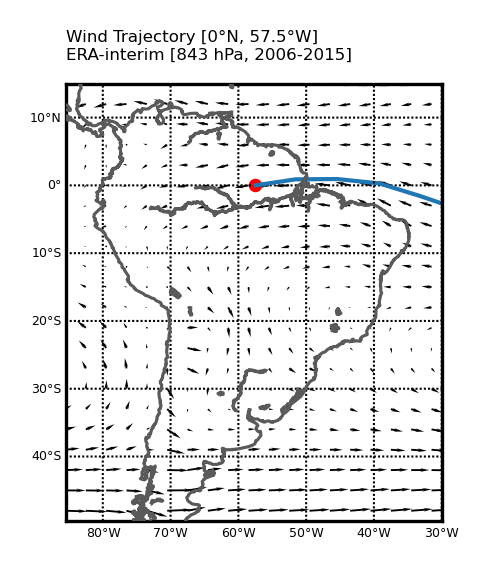

In [7]:
# import package
from warnings import simplefilter
simplefilter(action='ignore', category=DeprecationWarning)
import os
os.environ['PROJ_LIB'] = r'C:\Users\USER\anaconda3\Library\share\basemap'
from mpl_toolkits.basemap import Basemap
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt

# Calculate trajectory
u = np.load('u_0615_843.npy')
v = np.load('v_0615_843.npy')
lat_trajectory, lon_trajectory = calculate_trajectory([0,-57.5], -u, -v, 30, 86400)

# To get the grid information for plotting
mod = 'MOD_2001.nc'
rootgrp = nc.Dataset(mod)
latg = rootgrp.variables['latitude'][:]
long = rootgrp.variables['longitude'][:]
long2,latg2 = np.meshgrid(long,latg)

# Plot
fig, ax = plt.subplots(1, 1, figsize = [3, 2],dpi = 300)

# Basemap
m = Basemap(projection='cyl', resolution = "l",llcrnrlon=-85.5, llcrnrlat=-49.5, urcrnrlon=-30, urcrnrlat=15)
m.drawcoastlines(color = '#5A5A5A', linewidth=0.75, zorder = 8);
cx,cy = m(long2,latg2)  # convert to map projection coordinate

# Wind barb
gap = 2
m.quiver(cx[::gap,::gap], cy[::gap,::gap], u[::gap,::gap], v[::gap,::gap],color = 'black',width = 0.005, headaxislength = 4, headwidth = 2)

# Trajectory
plt.plot(lon_trajectory, lat_trajectory, label='Trajectory', linewidth = 1)

# Start point
plt.scatter(lon_trajectory[0], lat_trajectory[0], color='red', label='Start Point', s = 5)

# Plotting parameters
Ltitle = 'Wind Trajectory [0°N, 57.5°W]\nERA-interim [843 hPa, 2006-2015]'
ax.set_title(Ltitle, loc = 'left', fontsize = 4)

# Draw the longitude and latitude lines
parallels = np.arange(-50,20,10)
m.drawparallels(parallels, color = '#000000',labels=[1,0,0,0],fontsize=3, zorder = 1, linewidth = 0.5)

meridians = np.arange(0.,360.,10.)
m.drawmeridians(meridians, color = '#000000',labels=[0,0,0,1],fontsize=3, zorder = 2, linewidth = 0.5)

plt.tight_layout()
plt.show()